# Тестирование ГА - обычного и островного

Что нужно протестировать:
- Гиперпараметры: меняем их и строим график зависимости точности решения от размера матрицы. Точность решения определяется расстоянием до оптимального решения, которое возвращает функция ГА
- Улучшения островного ГА по сравнению с обычным. Сначала подбираем гиперпараметры, потом это


In [7]:
import lab1_test_migrations
import matplotlib.pyplot as plt
from lab1_test import run_ga
from itertools import permutations
import random

def generate_matrix(size: int, ideal:bool=False):
    """Генерирует матрицу чисел от 1 до 100 размера size*size
    **Параметры**:\n
    ideal - если True, то генерирует матрицу с ценами 1 по главной диагонали и 100 в остальных позициях"""
    matrix = []
    if ideal:
        matrix = [[100] * size for _ in range(size)] 
        for i in range(size):
            matrix[i][i] = 1
    else:
        matrix = [[random.randint(1, 100) for _ in range(size)] for _ in range(size)]
    return matrix

generate_matrix(4, False)


[[13, 89, 10, 43], [26, 47, 89, 43], [28, 88, 92, 91], [92, 1, 6, 46]]

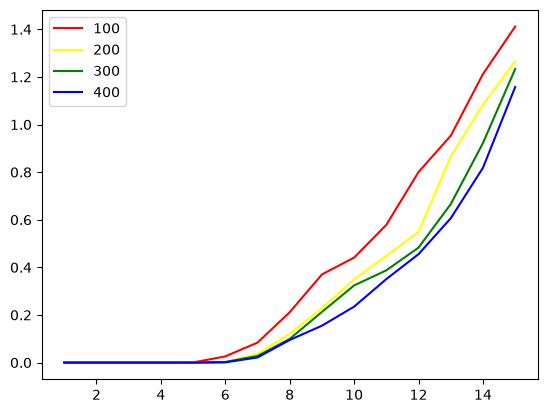

In [16]:
POPULATION_SIZE = 50  # Размер каждой популяции
MUTATION_PROBABILITY = 0.7
TOURNAMENT_SIZE = 2
MAX_ITERATIONS = 1000
PLATEAU_LIMIT = 3
PLATEAU_DIFF = 2e-4

data_x = list(range(1, 16))
data_y = []

def test_ga(sizes, iterations_number, algorythm, params, ideal = False):
    """Функция, тестирующая генетический алгоритм\n
    **Параметры**:\n
    sizes - массив размеров, для которых мы хотим протестировать ГА\n
    iterations_number - количество тестовых массивов, по которым мы усредняем результат ГА\n
    ?ideal - тестируем ли мы на идеальных матрицах"""

    y = [0] * len(sizes)
    for i in range(len(sizes)):
        for _ in range(iterations_number):
            matrix = generate_matrix(sizes[i], ideal)
            _, _, dist = algorythm(*params.values(), matrix=matrix)
            y[i] += dist
    y = [i / iterations_number for i in y]
    return y

usual_params = {
    "POPULATION_SIZE": 300,
    "MUTATION_PROBABILITY": 0.7,
    "MUTATION_PERCENT": 30,
    "TOURNAMENT_SIZE": 2,
    "MAX_ITERATIONS": 1000,
    "PLATEAU_LIMIT": 3,
    "PLATEAU_DIFF": 2e-4,
    "ELITIST_PERCENT": 0.2,
}

migration_params = {
    "POPULATION_SIZE": 300,
    "MUTATION_PROBABILITY": 0.7,
    "MUTATION_PERCENT": 0.3,
    "TOURNAMENT_SIZE": 2,
    "MAX_ITERATIONS": 1000,
    "PLATEAU_LIMIT": 3,
    "PLATEAU_DIFF": 2e-4,
    "MIGRATION_INTERVAL": 10,
    "MIGRATION_PERCENT": 10,
    "NUM_ISLANDS": 3
}

colors = ['red', 'yellow', 'green', 'blue', 'magenta', 'orange']

for i in range(1, 5):
    usual_params["POPULATION_SIZE"] = i * 100
    data_y = test_ga(data_x, 100, run_ga, usual_params)
    plt.plot(data_x, data_y, color=colors[i - 1], label=str(i * 100))

plt.legend()
plt.show()




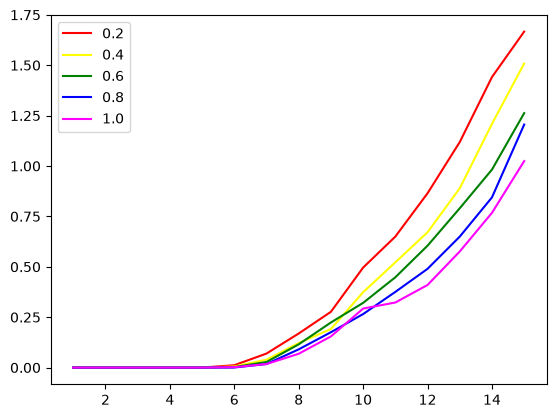

In [ ]:
# Вывод: оптимальный размер популяции - 200: ошибка не растет настолько быстро, как при 100, но и время исполнения остается приемлемым
usual_params["POPULATION_SIZE"] = 200
migration_params["POPULATION_SIZE"] = 200

for i in range(1, 6):
    usual_params["MUTATION_PROBABILITY"] = i / 5
    data_y = test_ga(data_x, 100, run_ga, usual_params)
    plt.plot(data_x, data_y, color=colors[i - 1], label=str(i/5))

plt.legend()
plt.show()

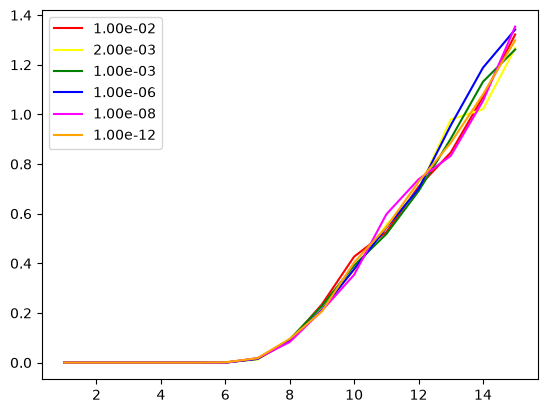

In [17]:
# Вывод: вероятность мутации так же влияет довольно сильно: чем она больше, тем меньше отклонение от оптимума
usual_params["MUTATION_PROBABILITY"] = 1.0
migration_params["MUTATION_PROBABILITY"] = 1.0
c = 0
for i in [1/100, 1/500, 1e-3, 1e-6, 1e-8, 1e-12]:
    usual_params["PLATEAU_DIFF"] = 1/i/100
    data_y = test_ga(data_x, 100, run_ga, usual_params)
    plt.plot(data_x, data_y, color=colors[c], label=f'{i:.2e}')
    c += 1

plt.legend()
plt.show()

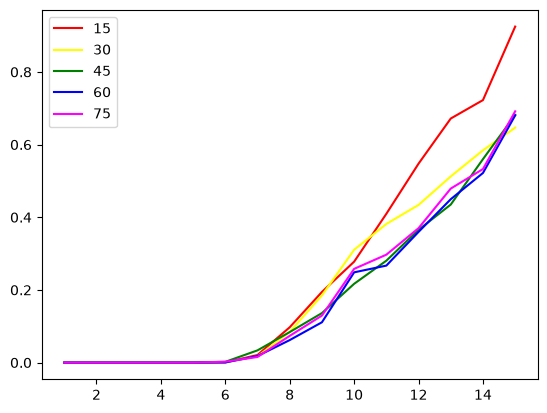

In [ ]:
## Вывод: значение размаха колебания плато не влияет на результат. Запуски на подобранных данных показали, что уже 
# после 10-20 итераций популяция размера 250 сходится к одному и тому же вектору, т.е. размах становится =0

usual_params["PLATEAU_DIFF"] = 1e-6
usual_params["MUTATION_PROBABILITY"] = 0.7

for i in range(1, 6):
    usual_params["MUTATION_PERCENT"] = i * 15
    data_y = test_ga(data_x, 100, run_ga, usual_params)
    plt.plot(data_x, data_y, color=colors[i - 1], label=str(i * 15))

plt.legend()
plt.show()

Возьмём размер инвертируемого вектора 45% от длины особи; однако можно отметить, что этот параметр не очень сильно влияет на результат, главное, чтобы он не был слишком мал.

## Тестирование островного ГА в сравнении с обычным

In [ ]:
migration_params["MUTATION_PERCENT"] = 45
usual_params["MUTATION_PERCENT"] = 45

for i in range(3, 9):
    migration_params["NUM_ISLANDS"] = i
    migration_params["POPULATION_SIZE"] = 300 // i
    data_y = test_ga(data_x, 100, lab1_test_migrations.run_ga_with_migrations, migration_params)
    plt.plot(data_x, data_y, color=colors[(i - 1) % 5], label=f'{i} островов')

plt.legend()
plt.show()

TypeError: run_ga_with_migrations() missing 1 required positional argument: 'elitist_percent'